# Taller: Regresión logística en Python

## Detección de cuentas falsas en Instagram

Las redes sociales tienen un problema constante con las cuentas falsas: perfiles creados para enviar spam, inflar seguidores o suplantar a otras personas. Revisarlas una por una es imposible, así que las plataformas usan modelos de clasificación que, a partir de datos públicos del perfil, estiman si una cuenta es real o falsa.

En este taller vas a construir uno de esos modelos con **regresión logística**, siguiendo el flujo de trabajo del tutorial de DataCamp *Understanding Logistic Regression in Python*, pero aplicado a un problema distinto.

**Al terminar el taller deberías poder:**

1. Explicar qué es la regresión logística y en qué se diferencia de la regresión lineal.
2. Describir el papel de la función sigmoide.
3. Entrenar un clasificador con `scikit-learn`.
4. Evaluarlo con matriz de confusión, precision, recall y curva ROC.

## 2. Regresión lineal frente a regresión logística

La regresión lineal produce un resultado **continuo**, como el precio de una casa o el número de seguidores que tendrá una cuenta el próximo mes. La regresión logística produce un resultado **discreto**, como decidir si una cuenta es falsa o no.

También difieren en cómo estiman sus coeficientes:

- La regresión lineal usa **mínimos cuadrados ordinarios (MCO)**: busca la recta que minimiza la suma de los errores al cuadrado.
- La regresión logística usa **estimación por máxima verosimilitud (MLE)**: busca los coeficientes que hacen más probable haber observado los datos que tenemos.

## 5. Construcción del modelo con scikit-learn

### 5.1 El conjunto de datos

Usaremos el dataset *Instagram fake spammer genuine accounts*, disponible en Kaggle:

https://www.kaggle.com/datasets/free4ever1/instagram-fake-spammer-genuine-accounts

Descarga el archivo `train.csv` y colócalo en la misma carpeta que este notebook. Cada fila corresponde a una cuenta de Instagram y contiene estas columnas:

| Columna original | Nombre en el taller | Significado |
|---|---|---|
| `profile pic` | `foto_perfil` | 1 si la cuenta tiene foto de perfil |
| `nums/length username` | `nums_usuario` | Proporción de dígitos en el nombre de usuario |
| `fullname words` | `palabras_nombre` | Número de palabras del nombre completo |
| `nums/length fullname` | `nums_nombre` | Proporción de dígitos en el nombre completo |
| `name==username` | `nombre_igual_usuario` | 1 si el nombre completo es igual al nombre de usuario |
| `description length` | `long_descripcion` | Número de caracteres de la biografía |
| `external URL` | `url_externa` | 1 si la biografía tiene un enlace externo |
| `private` | `privada` | 1 si la cuenta es privada |
| `#posts` | `publicaciones` | Número de publicaciones |
| `#followers` | `seguidores` | Número de seguidores |
| `#follows` | `seguidos` | Número de cuentas que sigue |
| `fake` | `falsa` | **Variable objetivo**: 1 si la cuenta es falsa |

### 5.2 Cargar los datos

Para trabajar con nombres más cortos y en español, reemplazamos los encabezados con `col_names` al leer el archivo con `read_csv()` de pandas.

In [9]:
import pandas as pd ;
import numpy as np
import matplotlib.pyplot as plt

#traducir los nomnbre de las columnas del archivo a español
col_names =['foto_perfil','nums_usuario',' palabras_nombre', 'nums_nombre','nombre_igual_usuario','long_descripcion','url_externa','privada', 'publicaciones','seguidores','seguidos','falsa']

cuentas = pd.read_csv('train.csv', header = 0, names = col_names)

In [10]:
#mostrar las primeras 5 filas
cuentas.head()

,foto_perfil,nums_usuario,palabras_nombre,nums_nombre,nombre_igual_usuario,long_descripcion,url_externa,privada,publicaciones,seguidores,seguidos,falsa
0,1,0.27,0,0.0,0,53,0,0,32,1000,955,0
1,1,0.00,2,0.0,0,44,0,0,286,2740,533,0
2,1,0.10,2,0.0,0,0,0,1,13,159,98,0
3,1,0.00,1,0.0,0,82,0,0,679,414,651,0
4,1,0.00,2,0.0,0,0,0,1,6,151,126,0


### 5.3 Seleccionar las características

Ahora dividimos las columnas en dos grupos: la **variable dependiente** u objetivo (`falsa`) y las **variables independientes** o características, que el modelo usará para predecir.

In [11]:
feature_cols = ['foto_perfil','nums_usuario',' palabras_nombre', 'nums_nombre','nombre_igual_usuario','long_descripcion','url_externa','privada', 'publicaciones','seguidores','seguidos'] 

X = cuentas[feature_cols]

#Y contiene la respuesta correcta de cada fila 0 = cuenta real, 1 = cuenta falsa
y = cuentas.falsa

### 5.4 Dividir los datos

Para medir el rendimiento del modelo con datos que no vio durante el entrenamiento, dividimos el conjunto en dos partes con `train_test_split()`. Le pasamos las características, la variable objetivo y el tamaño del conjunto de prueba. Con `random_state` fijamos la selección aleatoria para que todos obtengan el mismo resultado.

In [ ]:
from sklearn.model_selection import train_test_split

#separar las mismas filas de X u Y para que cada cuenta conserve su etiqueta 
#el 25% va a quedar reservado para probar el modelo con datos que no uso para aprender

#random_state fija el azar y permite repetir la misma division 
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state= 16) 


El 75 % de las cuentas se usará para entrenar el modelo y el 25 % para probarlo.

### 5.5 Desarrollo del modelo y predicción

Importamos `LogisticRegression`, creamos el clasificador con `random_state` para que sea reproducible, lo entrenamos con `fit()` y hacemos predicciones sobre el conjunto de prueba con `predict()`.

In [ ]:
from sklearn.linear_model import LogisticRegression
#creamos el clasificador, max_iter permitir mas pasos para se realiza el aprendizaje 
logreg = LogisticRegression(random_state=16, max_iter=5000)

#usar fit para comparar las caracteristicas (x_train) cpm ña respuesta (y_train)
#internamente la reg logistica, convierte su calculo en una probabilidad  entre 0 y 1 usando la sigmoide. los coeficientes los va a aprender el modelo durante el entrenamiento
logreg.fit(X_train, y_train)

#predict asigno una clase a cada cuenta ( 0= real, 1= falsa).
#Por defecto, la desicion del umbral a usar es de 0.5
y_pred = logreg.predict(X_test)

#imprimo los mejores coeficientes que el modelo obtuvo luego de su entrenamiento
print(logreg.coef_)
print(logreg.intercept_)

[[-3.04876928e+00  3.54206406e+00 -3.70315446e-01  7.35034288e-01
   9.07117835e-01 -9.75088016e-03 -1.19219661e+00 -3.74821435e-01
  -1.11274397e-02 -2.12589914e-03  7.51872484e-04]]
[3.74724104]


## 6. Evaluación del modelo con la matriz de confusión

La matriz de confusión es una tabla que resume cuántas predicciones fueron correctas e incorrectas para cada clase. Como el problema es binario, la matriz es de 2 × 2.

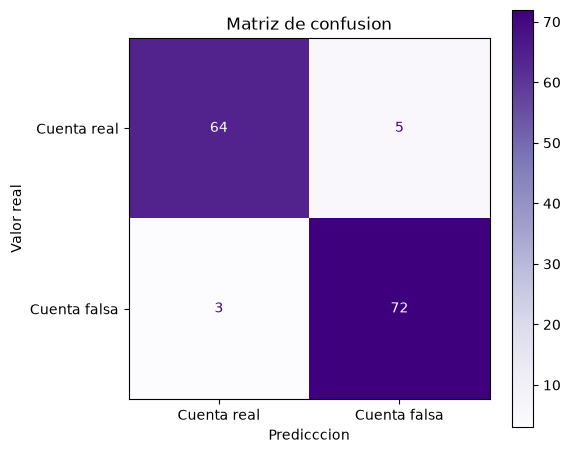

In [ ]:
from sklearn import metrics
#vamos a comparar las repuestas reales (y_test) con las predicciones del modelo 
#la matriz organiza los aciertos y errores por clase: filas reales, columnas predichas

cnf_matrix=metrics.confusion_matrix(y_test, y_pred )
cm_display = metrics.ConfusionMatrixDisplay(confusion_matrix = cnf_matrix, display_labels = ['Cuenta real', 'Cuenta falsa']) 
cnf_matrix = metrics
#Dibujar la matriz para ver los tipos de error que ocurrieron 
fig, ax = plt.subplots(figsize=(6, 5))
cm_display.plot (ax=ax, cmap ="Purples",values_format = 'd', colorbar=True)
ax.set_title('Matriz de confusion')
ax.set_xlabel('Predicccion')
ax.set_ylabel('Valor real')
plt.tight_layout()
plt.show()


Los valores de la diagonal principal son las predicciones correctas y los de fuera de la diagonal son los errores. La fila indica la clase real y la columna la clase predicha:

| | Predicha real (0) | Predicha falsa (1) |
|---|---|---|
| **Real (0)** | Verdaderos negativos | Falsos positivos |
| **Falsa (1)** | Falsos negativos | Verdaderos positivos |

### 6.1 Métricas de evaluación

Con `classification_report` obtenemos accuracy, precision y recall para cada clase.

In [ ]:
from sklearn.metrics import classification_report

target_names = ['cuenta real', 'cuenta falsa']

#el reporte va a resumir precision, recall, etc de cada clase  
print(classification_report(y_test, y_pred, target_names=target_names))

              precision    recall  f1-score   support

 cuenta real       0.96      0.93      0.94        69
cuenta falsa       0.94      0.96      0.95        75

    accuracy                           0.94       144
   macro avg       0.95      0.94      0.94       144
weighted avg       0.94      0.94      0.94       144



Cómo leer las métricas de la clase *cuenta falsa*:

- **Accuracy:** proporción de cuentas clasificadas correctamente, sin importar la clase.
- **Precision:** de todas las cuentas que el modelo marcó como falsas, ¿qué proporción realmente lo era? Una precision baja significaría que el modelo acusa a muchas cuentas reales.
- **Recall:** de todas las cuentas falsas que había en el conjunto de prueba, ¿qué proporción detectó el modelo? Un recall bajo significaría que muchas cuentas falsas pasan desapercibidas.

Anota los valores que obtuviste; los necesitarás en las actividades.

## 7. Curva ROC

La curva ROC (*Receiver Operating Characteristic*) grafica la tasa de verdaderos positivos frente a la tasa de falsos positivos para todos los puntos de corte posibles. Muestra el equilibrio entre sensibilidad y especificidad.

El área bajo la curva (**AUC**) resume la curva en un solo número: 1 representa un clasificador perfecto y 0.5 uno que no es mejor que lanzar una moneda.

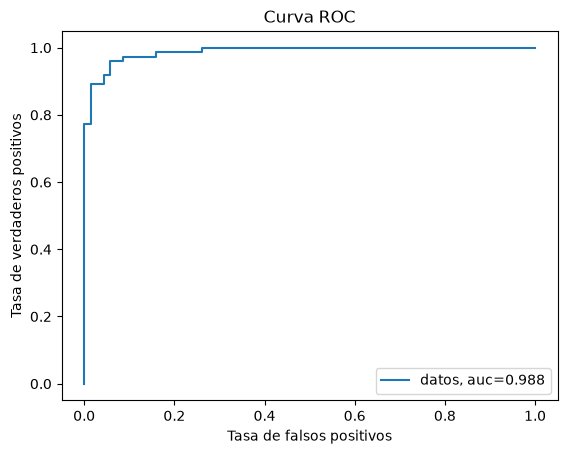

In [36]:
#predict_proba devuelve dos probabilidad, clase 0 y clase 1
#[::,1 ] tomar la probabilidad de que cada cuenta pertenezca a la clase 1 (falsa)
y_pred_proba = logreg.predict_proba(X_test)[::,1]

#la curva ROC mostrara aciertos y falsas alarmas al variar el umbral de decision

fpr, tpr, _ = metrics.roc_curve(y_test,  y_pred_proba)

#AUC resume esa curva : 1 es una separacion perfecta , 0,5 equivale al azar
auc = metrics.roc_auc_score(y_test, y_pred_proba)

#graficamos la tasa de falsos positivos frente a la de verdaderos positivos
plt.plot(fpr,tpr,label="datos, auc="+str(round(auc,3)))
plt.legend(loc=4)
plt.xlabel("Tasa de falsos positivos")
plt.ylabel("Tasa de verdaderos positivos")
plt.title("Curva ROC")
plt.show()

### Actividad . Clasificar una cuenta nueva

Una cuenta no tiene foto de perfil, el 40 % de su nombre de usuario son dígitos, su nombre completo tiene 1 palabra sin dígitos y es distinto del nombre de usuario, no tiene biografía ni enlace externo, es pública, tiene 0 publicaciones, 12 seguidores y sigue a 1 500 cuentas.

Usa `logreg.predict()` y `logreg.predict_proba()` para clasificarla. ¿Qué probabilidad asigna el modelo a que sea falsa?

In [47]:
#los valores irian en el mismo orden que el feature_cols, cada posiscion representa una caracteristica

nueva_cuenta = pd.DataFrame([[0,0.40,1,0,0,0,0,0,0,12,1500]], columns=feature_cols)
#predict entrega la clase elegida, con la posibilidad de cada clase

clase = logreg.predict(nueva_cuenta)[0]
proba = logreg.predict_proba(nueva_cuenta)[0]

print("Prediccion: ", "cuenta falsa" if clase == 1 else "cuenta real")

#en proba, la posicion 0 es la probabilidad de cuenta real y la 1 de cuenta falsa 

print (f"Probabilidad de cuenta real : {proba[0]: .3f}") 


Prediccion:  cuenta falsa
Probabilidad de cuenta real :  0.003
